# Problem 1

**Khám phá mối quan hệ giữa vị trí công việc và kỹ năng chuyên môn.** Luật có dạng `ROLE → skill`. So sánh Apriori và FP-Growth với baseline kỹ năng phổ biến toàn cục; đánh giá gợi ý trên các tin tuyển dụng giữ lại khỏi tập huấn luyện.

## 1. Nạp dữ liệu

Ma trận giao dịch và dữ liệu nhãn phải có cùng số dòng, cùng thứ tự. `skills_final` được parse thành list trước khi dùng làm ground truth.

In [19]:
import ast
import json
import math
import statistics
import time
import tracemalloc
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlxtend.frequent_patterns import apriori, association_rules, fpgrowth
from sklearn.model_selection import train_test_split

DATA_DIR = Path("../data/processed")
MATRIX_PATH = DATA_DIR / "transaction_matrix.csv"
JOBS_PATH = DATA_DIR / "processed_jobs.csv"
RANDOM_STATE = 42
TEST_SIZE = 0.20
MIN_CONFIDENCE = 0.20
MIN_LIFT = 1.0
MAX_ITEMSET_LENGTH = 4  # ROLE + tối đa 3 kỹ năng trong một luật
N_BENCHMARK_RUNS = 3
TOP_K_VALUES = [5, 10]
RESULT_DIR = Path("../result/problem_1")
FIGURES_DIR = RESULT_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def parse_skill_list(value):
    if isinstance(value, list):
        return [skill.strip() for skill in value if isinstance(skill, str) and skill.strip()]
    if pd.isna(value):
        return []
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
        except (ValueError, SyntaxError):
            return []
        if isinstance(parsed, list):
            return [skill.strip() for skill in parsed if isinstance(skill, str) and skill.strip()]
    return []


df = pd.read_csv(JOBS_PATH)
df["skills_final"] = df["skills_final"].apply(parse_skill_list)
df = df[df["role_group"].fillna("Other") != "Other"].reset_index(drop=True)
transaction_df = pd.read_csv(MATRIX_PATH).replace({"True": True, "False": False}).fillna(False).astype(bool)

if len(df) != len(transaction_df):
    raise ValueError(
        f"Số dòng không khớp: processed_jobs={len(df)}, transaction_matrix={len(transaction_df)}. "
        "Hãy tái tạo hai file từ cùng một dataframe đã lọc, cùng thứ tự."
    )

role_cols = [column for column in transaction_df.columns if column.startswith("ROLE_")]
skill_cols = [column for column in transaction_df.columns if not column.startswith("ROLE_")]
if not role_cols:
    raise ValueError("Transaction matrix không có cột ROLE_*. Hãy kiểm tra bước tạo ma trận.")

matrix_role = transaction_df[role_cols].idxmax(axis=1).str.replace("ROLE_", "", n=1, regex=False)
if not matrix_role.equals(df["role_group"].reset_index(drop=True)):
    raise ValueError("Thứ tự role_group không khớp với các cột ROLE_ trong transaction matrix.")

print("Jobs:", len(df), "| skill columns:", len(skill_cols), "| roles:", df["role_group"].nunique())


Jobs: 1830 | skill columns: 200 | roles: 10


## 2. Chia train/test theo vị trí

Chia trong từng `role_group` để mỗi vị trí có thể xuất hiện ở cả train và test. Mô hình chỉ học từ train. Ground truth dùng list kỹ năng đã parse, không dùng chuỗi ký tự.

In [20]:
all_indices = np.arange(len(df))
train_indices, test_indices = train_test_split(
    all_indices,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=df["role_group"],
)

train_df = df.iloc[train_indices].reset_index(drop=True)
test_df = df.iloc[test_indices].reset_index(drop=True)
train_matrix = transaction_df.iloc[train_indices].reset_index(drop=True)
test_matrix = transaction_df.iloc[test_indices].reset_index(drop=True)

print("Train:", len(train_df), "| Test:", len(test_df))
print("Train roles:", train_df["role_group"].nunique())


Train: 1464 | Test: 366
Train roles: 10


## 3. Khai phá luật và đo Runtime/Memory

Support tự điều chỉnh theo nhóm role nhỏ nhất để luật role–skill đủ support khi kỹ năng đạt confidence tối thiểu. Mỗi itemset tối đa 4 phần tử, nên luật có dạng `ROLE → {skill}` đến `ROLE → {skill 1, skill 2, skill 3}`. Runtime tính cả khai phá itemsets và tạo/lọc luật. Thời gian báo cáo là trung vị của ba lần chạy; memory là peak Python allocation từ `tracemalloc` (không gồm đầy đủ bộ nhớ native).

In [21]:
role_train_counts = train_df["role_group"].value_counts()
MIN_SUPPORT = max(
    (role_train_counts.min() * MIN_CONFIDENCE) / len(train_df),
    1 / len(train_df),
)


def fit_association_model(method, repeats=N_BENCHMARK_RUNS):
    durations, peak_memory_mb = [], []
    final_itemsets, final_rules = None, None

    for _ in range(repeats):
        tracemalloc.start()
        started = time.perf_counter()
        if method == "Apriori":
            itemsets = apriori(
                train_matrix,
                min_support=MIN_SUPPORT,
                use_colnames=True,
                max_len=MAX_ITEMSET_LENGTH,
            )
        elif method == "FP-Growth":
            itemsets = fpgrowth(
                train_matrix,
                min_support=MIN_SUPPORT,
                use_colnames=True,
                max_len=MAX_ITEMSET_LENGTH,
            )
        else:
            tracemalloc.stop()
            raise ValueError("method phải là 'Apriori' hoặc 'FP-Growth'.")

        if itemsets.empty or not itemsets["itemsets"].map(len).ge(2).any():
            direct_rules = pd.DataFrame(columns=["role_group", "skills", "support", "confidence", "lift"])
        else:
            all_rules = association_rules(
                itemsets,
                metric="confidence",
                min_threshold=MIN_CONFIDENCE,
            )
            if all_rules.empty:
                direct_rules = pd.DataFrame(columns=["role_group", "skills", "support", "confidence", "lift"])
            else:
                direct_rules = all_rules[
                    all_rules["antecedents"].map(
                        lambda items: len(items) == 1 and str(next(iter(items))).startswith("ROLE_")
                    )
                    & all_rules["consequents"].map(
                        lambda items: len(items) >= 1
                        and all(not str(item).startswith("ROLE_") for item in items)
                    )
                    & (all_rules["lift"] >= MIN_LIFT)
                ].copy()
                direct_rules["role_group"] = direct_rules["antecedents"].map(
                    lambda items: str(next(iter(items))).replace("ROLE_", "", 1)
                )
                direct_rules["skills"] = direct_rules["consequents"].map(
                    lambda items: tuple(sorted(items))
                )
                direct_rules = direct_rules.sort_values(
                    ["confidence", "lift", "support"], ascending=False
                )

        durations.append(time.perf_counter() - started)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_memory_mb.append(peak / (1024 ** 2))
        final_itemsets, final_rules = itemsets, direct_rules

    return {
        "itemsets": final_itemsets,
        "rules": final_rules,
        "runtime_seconds": statistics.median(durations),
        "memory_mb": statistics.median(peak_memory_mb),
    }


apriori_result = fit_association_model("Apriori")
fp_result = fit_association_model("FP-Growth")

print("min_support:", round(MIN_SUPPORT, 6))
print("Apriori rules:", len(apriori_result["rules"]))
print("FP-Growth rules:", len(fp_result["rules"]))


min_support: 0.002322
Apriori rules: 94
FP-Growth rules: 94


## 4. Baseline độc lập

Baseline xếp kỹ năng theo tần suất toàn cục trong train, không dùng role. Cả baseline và hai mô hình dùng cùng các cột kỹ năng của transaction matrix.

In [22]:
def global_popularity_baseline(repeats=N_BENCHMARK_RUNS):
    durations, peak_memory_mb = [], []
    final_ranking = None
    for _ in range(repeats):
        tracemalloc.start()
        started = time.perf_counter()
        counts = train_matrix[skill_cols].sum(axis=0).sort_values(ascending=False)
        final_ranking = counts.index.tolist()
        durations.append(time.perf_counter() - started)
        _, peak = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        peak_memory_mb.append(peak / (1024 ** 2))
    return final_ranking, statistics.median(durations), statistics.median(peak_memory_mb)


baseline_ranking, baseline_runtime, baseline_memory = global_popularity_baseline()

def role_rankings(rule_table):
    rankings = {}
    if rule_table.empty:
        return rankings
    for role, group in rule_table.groupby("role_group"):
        expanded = []
        for _, rule in group.sort_values(
            ["confidence", "lift", "support"], ascending=False
        ).iterrows():
            expanded.extend(rule["skills"])
        rankings[role] = list(dict.fromkeys(expanded))
    return rankings


apriori_rankings = role_rankings(apriori_result["rules"])
fp_rankings = role_rankings(fp_result["rules"])
baseline_rankings = {role: baseline_ranking for role in train_df["role_group"].unique()}


## 5. Đánh giá Recommendation Quality

Với từng tin test, gợi ý được chọn theo role; kỹ năng thực tế là ground truth. Precision@K chia cho K cố định, Recall@K đo phần kỹ năng thực tế được tìm lại, NDCG@K tính thứ tự xếp hạng. Tin không có luật gợi ý vẫn được tính với điểm 0 để thể hiện độ bao phủ của hệ thống.

In [23]:
def topk_metrics(prediction, relevant, k):
    relevant = set(relevant) & set(skill_cols)
    if not relevant:
        return None
    prediction = list(dict.fromkeys(prediction))[:k]
    hits = [int(skill in relevant) for skill in prediction]
    precision = sum(hits) / k
    recall = sum(hits) / len(relevant)
    dcg = sum(hit / math.log2(rank + 2) for rank, hit in enumerate(hits))
    ideal_hits = min(k, len(relevant))
    idcg = sum(1 / math.log2(rank + 2) for rank in range(ideal_hits))
    ndcg = dcg / idcg if idcg else 0.0
    return precision, recall, ndcg, int(any(hits)), len(prediction) / k


def evaluate_rankings(rankings, k):
    scores = []
    for _, row in test_df.iterrows():
        role = row["role_group"]
        actual = row["skills_final"]
        result = topk_metrics(rankings.get(role, []), actual, k)
        if result is not None:
            scores.append(result)
    if not scores:
        return {"Precision@K": 0.0, "Recall@K": 0.0, "NDCG@K": 0.0, "Hit@K": 0.0, "Recommendation coverage": 0.0, "Test jobs": 0}
    values = np.asarray(scores)
    return {
        "Precision@K": values[:, 0].mean(),
        "Recall@K": values[:, 1].mean(),
        "NDCG@K": values[:, 2].mean(),
        "Hit@K": values[:, 3].mean(),
        "Recommendation coverage": values[:, 4].mean(),
        "Test jobs": len(scores),
    }


quality_rows = []
for k in TOP_K_VALUES:
    for name, rankings in [
        ("Apriori", apriori_rankings),
        ("FP-Growth", fp_rankings),
        ("Baseline: global popularity", baseline_rankings),
    ]:
        quality_rows.append({"Model": name, "K": k, **evaluate_rankings(rankings, k)})
quality_df = pd.DataFrame(quality_rows)
quality_df


,Model,K,Precision@K,Recall@K,NDCG@K,Hit@K,Recommendation coverage,Test jobs
0,Apriori,5,0.255921,0.258712,0.352988,0.598684,0.625000,304
1,FP-Growth,5,0.255921,0.258712,0.352988,0.598684,0.625000,304
2,Baseline: global popularity,5,0.164474,0.193582,0.227594,0.516447,1.000000,304
3,Apriori,10,0.151645,0.287106,0.333243,0.625000,0.411513,304
4,FP-Growth,10,0.151645,0.287106,0.333243,0.625000,0.411513,304
5,Baseline: global popularity,10,0.133224,0.263715,0.256813,0.684211,1.000000,304


## 6. Bảng tổng hợp Runtime, Number of Rules, Memory Usage

Baseline không sinh luật nên Number of Rules để trống. Các số đo Runtime và Memory là trung vị của ba lần chạy trong cùng môi trường.

In [24]:
resource_df = pd.DataFrame([
    {"Model": "Apriori", "Runtime (s)": apriori_result["runtime_seconds"],
     "Number of Rules": len(apriori_result["rules"]), "Memory Usage (MB)": apriori_result["memory_mb"]},
    {"Model": "FP-Growth", "Runtime (s)": fp_result["runtime_seconds"],
     "Number of Rules": len(fp_result["rules"]), "Memory Usage (MB)": fp_result["memory_mb"]},
    {"Model": "Baseline: global popularity", "Runtime (s)": baseline_runtime,
     "Number of Rules": np.nan, "Memory Usage (MB)": baseline_memory},
])
resource_df


,Model,Runtime (s),Number of Rules,Memory Usage (MB)
0,Apriori,11.014090,94.0,208.159354
1,FP-Growth,11.350139,94.0,143.533943
2,Baseline: global popularity,0.002587,NaN,0.342033


## 7. Biểu đồ so sánh

Biểu đồ tài nguyên tách riêng số luật vì baseline không sinh luật. Biểu đồ Recommendation Quality so Precision@K, Recall@K, Hit@K và NDCG@K tại từng K.

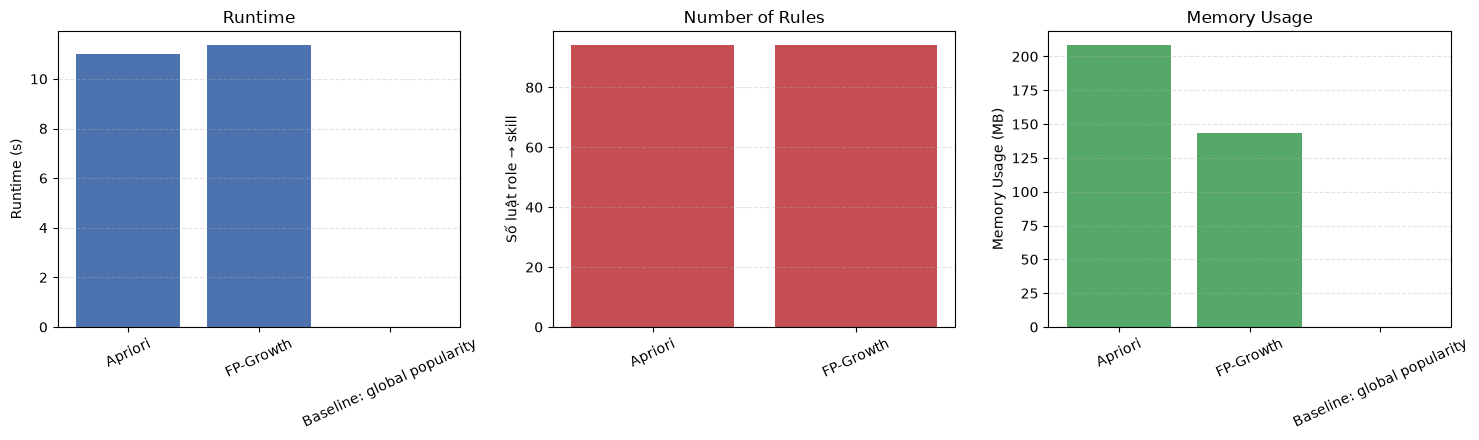

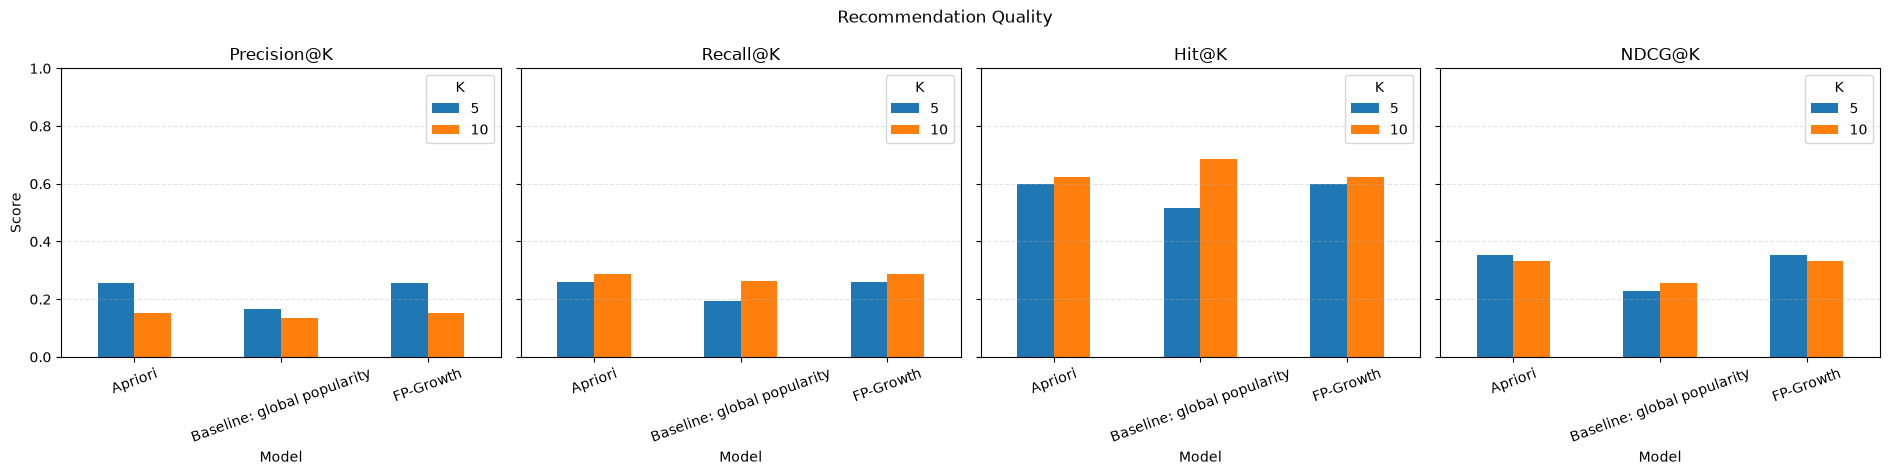

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

resource_models = resource_df["Model"]
for ax, metric, title, color in [
    (axes[0], "Runtime (s)", "Runtime", "#4C72B0"),
    (axes[2], "Memory Usage (MB)", "Memory Usage", "#55A868"),
]:
    ax.bar(resource_models, resource_df[metric], color=color)
    ax.set_title(title)
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=25)
    ax.grid(axis="y", linestyle="--", alpha=0.35)

rule_models = resource_df.dropna(subset=["Number of Rules"])
axes[1].bar(rule_models["Model"], rule_models["Number of Rules"], color="#C44E52")
axes[1].set_title("Number of Rules")
axes[1].set_ylabel("Số luật role → skill")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "resource_benchmark.png", dpi=180, bbox_inches="tight")
plt.show()

quality_metrics = ["Precision@K", "Recall@K", "Hit@K", "NDCG@K"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.8), sharey=True)
for ax, metric in zip(axes, quality_metrics):
    pivot = quality_df.pivot(index="Model", columns="K", values=metric)
    pivot.plot(kind="bar", ax=ax, ylim=(0, 1), rot=20)
    ax.set_title(metric)
    ax.set_ylabel("Score")
    ax.grid(axis="y", linestyle="--", alpha=0.35)
    ax.legend(title="K")
fig.suptitle("Recommendation Quality")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "recommendation_quality.png", dpi=180, bbox_inches="tight")
plt.show()


## 8. Kiểm tra tính nhất quán và diễn giải

Apriori và FP-Growth nên tìm cùng frequent itemsets và luật khi dùng cùng tham số; so Runtime/Memory để chọn thuật toán phù hợp. Nếu baseline tốt hơn, điều đó cho thấy luật chưa cải thiện việc xếp hạng so với độ phổ biến chung. `Hit@K` đo tỷ lệ tin test có ít nhất một kỹ năng đúng trong top K; `Recommendation coverage` cho biết hệ thống đã lấp được bao nhiêu vị trí gợi ý. Các bảng và biểu đồ được xuất trong thư mục `result/problem_1/`.

In [26]:
def rule_map(result):
    if result["itemsets"].empty:
        return {}
    return {
        frozenset(items): float(support)
        for items, support in zip(result["itemsets"]["itemsets"], result["itemsets"]["support"])
    }

apriori_map = rule_map(apriori_result)
fp_map = rule_map(fp_result)
print("Apriori/FP-Growth frequent itemsets giống nhau:", set(apriori_map) == set(fp_map))
print("Số itemsets chỉ Apriori:", len(set(apriori_map) - set(fp_map)))
print("Số itemsets chỉ FP-Growth:", len(set(fp_map) - set(apriori_map)))


Apriori/FP-Growth frequent itemsets giống nhau: True
Số itemsets chỉ Apriori: 0
Số itemsets chỉ FP-Growth: 0


## 9. Xuất kết quả

Các bảng luật, chỉ số chất lượng và benchmark được xuất thành CSV trong `result/problem_1/`; biểu đồ nằm trong `result/problem_1/figures/`. Chạy notebook từ đầu để cập nhật toàn bộ kết quả.

In [27]:
def export_rule_table(result, output_path):
    export_df = result["rules"][["role_group", "skills", "support", "confidence", "lift"]].copy()
    export_df["skills"] = export_df["skills"].map(
        lambda skills: json.dumps(list(skills), ensure_ascii=False)
    )
    export_df["rule_length"] = export_df["skills"].map(
        lambda value: len(json.loads(value)) + 1
    )
    export_df.to_csv(output_path, index=False, encoding="utf-8-sig")

export_rule_table(apriori_result, RESULT_DIR / "rules_apriori.csv")
export_rule_table(fp_result, RESULT_DIR / "rules_fpgrowth.csv")
quality_df.to_csv(RESULT_DIR / "quality_metrics.csv", index=False, encoding="utf-8-sig")
resource_df.to_csv(RESULT_DIR / "benchmark.csv", index=False, encoding="utf-8-sig")
print("Đã xuất kết quả tại:", RESULT_DIR.resolve())


Đã xuất kết quả tại: D:\DataMining\skill-recommendation-using-association-rules\result\problem_1
